## COMET + BLEU + TRAINING CODE
- BASE: https://www.kaggle.com/code/pritepakorn/practical-project-manga-translation
- unsloth-bnb: https://www.kaggle.com/code/pritepakorn/practical-project-manga-translation?scriptVersionId=300085689
- bnb: https://www.kaggle.com/code/pritepakorn/practical-project-manga-translation?scriptVersionId=299790553

In [4]:
import pandas as pd

### unsloth/Qwen3-14B-Base-unsloth-bnb-4bit

In [5]:
df_base = pd.read_csv('manga_translation_evaluation_results_qwen_base.csv')
df_base

,Japanese Source,Real Thai (Reference),AI Thai (Prediction),Gemini Score
0,葬儀屋さんも冗談とか言うんですか,คุณสัปเหร่อ... ล้อเล่นใช่ไหมครับ,พูดเล่นงั้นเหรอ?,4
1,華鏡丸ーー!!,คาเคียวมารุ--!!,คาเคียวมารุ...!!,5
2,なんだこりゃあ...,อะไรเนี่ย,นี่มันบ้าอะไรกันเนี่ย...,9
3,今日は沢山買い物して喜んで,และวันนี้ เขาก็กำลังสนุกกับการช้อปปิ้ง,วันนี้ฉันช้อปปิ้งเยอะมากเลยนะ,3
4,こ,ค...,ค... คุณ,3
...,...,...,...,...
142,いいって言ったじゃないですか,ก็บอกแล้วไงว่าไม่เป็นไร!,ฉันบอกนายว่าไม่เป็นไรนี่นา,9
143,店長!,ผู้จัดการ!,ผู้จัดการ!,10
144,...,ไม่มีข้อความต้นฉบับ (ญี่ปุ่นและอังกฤษ) โปรดระบ...,...,1
145,うちの近所じゃなくてよかった〜,ดีนะที่ไม่ใช่แถวบ้านฉัน,โชคดีที่ไม่ได้เกิดที่บ้านนะเนี่ย,6


In [6]:
df_base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147 entries, 0 to 146
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Japanese Source        147 non-null    object
 1   Real Thai (Reference)  147 non-null    object
 2   AI Thai (Prediction)   147 non-null    object
 3   Gemini Score           147 non-null    int64 
dtypes: int64(1), object(3)
memory usage: 4.7+ KB


In [7]:
df_base.describe()

,Gemini Score
count,147.000000
mean,5.299320
std,3.340115
min,1.000000
25%,2.000000
50%,4.000000
75%,9.000000
max,10.000000


In [8]:
average_score = df_base['Gemini Score'].mean()
average_score.round(2)

np.float64(5.3)

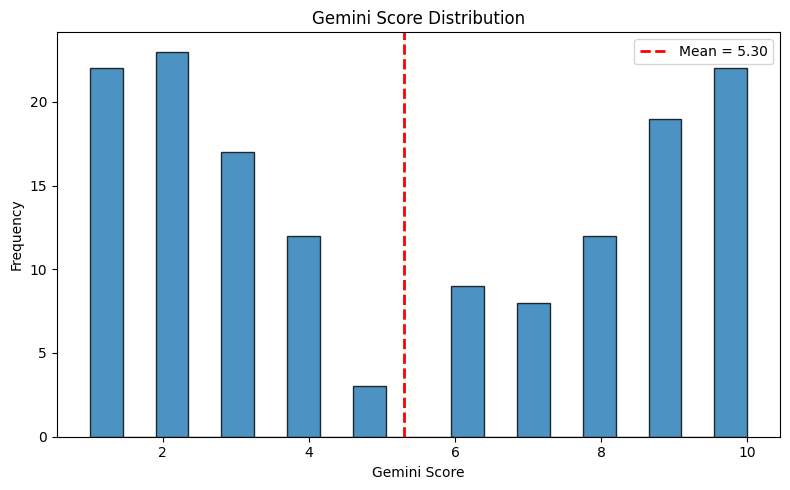

In [9]:
import matplotlib.pyplot as plt

score_col = 'Gemini Score'
scores = pd.to_numeric(df_base[score_col], errors='coerce').dropna()

plt.figure(figsize=(8, 5))
plt.hist(scores, bins=20, edgecolor='black', alpha=0.8)
plt.axvline(scores.mean(), color='red', linestyle='--', linewidth=2, label=f"Mean = {scores.mean():.2f}")
plt.title('Gemini Score Distribution')
plt.xlabel('Gemini Score')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

This graph means that the min is 0 and the max is 10, while the mean is 5.3, and the median (middle of data) is at 4, with 25% of the data being below 2 and 75% of the data being below 9

- Right-Skewed Distribution: Since the mean (5.3) is higher than the median (4), your data is "right-skewed." This means there are some high scores (between 9 and 10) that are pulling the average up, even though half of the scores are 4 or lower.
- The "Spread": The box represents the Interquartile Range (IQR), which is $9 - 2 = 7$. This shows that the middle 50% of your Gemini scores are quite spread out across the scale.
- Density: The fact that the median (4) is closer to the left side of the box (2) than the right (9) suggests that the data points between the 25th and 50th percentiles are more "bunched up" than those between the 50th and 75th percentiles.

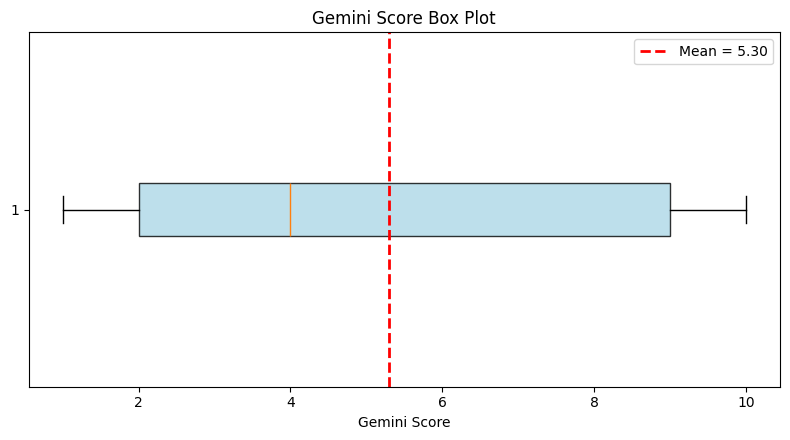

In [10]:
plt.figure(figsize=(8, 4.5))
plt.boxplot(scores, vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue', alpha=0.8))
plt.axvline(scores.mean(), color='red', linestyle='--', linewidth=2, label=f"Mean = {scores.mean():.2f}")
plt.title('Gemini Score Box Plot')
plt.xlabel('Gemini Score')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# unsloth/Qwen3-14B-unsloth-bnb-4bit

In [12]:
df_unsloth = pd.read_csv('manga_translation_evaluation_results_qwen_unsloth.csv')
df_unsloth

,Japanese Source,Real Thai (Reference),AI Thai (Prediction),Gemini Score
0,葬儀屋さんも冗談とか言うんですか,คุณสัปเหร่อ... ล้อเล่นใช่ไหมครับ,พูดตลกได้ด้วยเหรอเนี่ย,2
1,華鏡丸ーー!!,คาเคียวมารุ--!!,คาเคียวมารุ!!,9
2,なんだこりゃあ...,อะไรเนี่ย,นี่มันอะไรกัน...,9
3,今日は沢山買い物して喜んで,และวันนี้ เขาก็กำลังสนุกกับการช้อปปิ้ง,ไปช้อปปิ้งกันเยอะๆ นะ,1
4,こ,ค...,คุณ...,2
...,...,...,...,...
142,いいって言ったじゃないですか,ก็บอกแล้วไงว่าไม่เป็นไร!,ฉันว่ามันไม่เลวเลยนะ,1
143,店長!,ผู้จัดการ!,ผู้จัดการ!,10
144,...,ไม่มีข้อความต้นฉบับ (ญี่ปุ่นและอังกฤษ) โปรดระบ...,...,1
145,うちの近所じゃなくてよかった〜,ดีนะที่ไม่ใช่แถวบ้านฉัน,ก็ดีนะที่ไม่ใช่บ้านเรา,8


In [13]:
df_unsloth.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147 entries, 0 to 146
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Japanese Source        147 non-null    object
 1   Real Thai (Reference)  147 non-null    object
 2   AI Thai (Prediction)   147 non-null    object
 3   Gemini Score           147 non-null    int64 
dtypes: int64(1), object(3)
memory usage: 4.7+ KB


In [14]:
df_unsloth.describe()

,Gemini Score
count,147.00000
mean,4.62585
std,3.46847
min,1.00000
25%,1.00000
50%,3.00000
75%,9.00000
max,10.00000


In [15]:
average_score_unsloth = df_unsloth['Gemini Score'].mean()
average_score_unsloth.round(2)

np.float64(4.63)

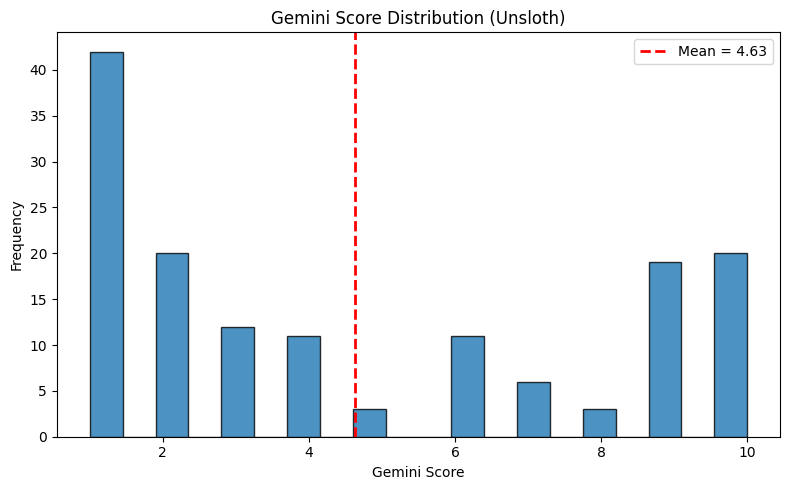

In [16]:
score_col = 'Gemini Score'
scores_unsloth = pd.to_numeric(df_unsloth[score_col], errors='coerce').dropna()

plt.figure(figsize=(8, 5))
plt.hist(scores_unsloth, bins=20, edgecolor='black', alpha=0.8)
plt.axvline(scores_unsloth.mean(), color='red', linestyle='--', linewidth=2, label=f"Mean = {scores_unsloth.mean():.2f}")
plt.title('Gemini Score Distribution (Unsloth)')
plt.xlabel('Gemini Score')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

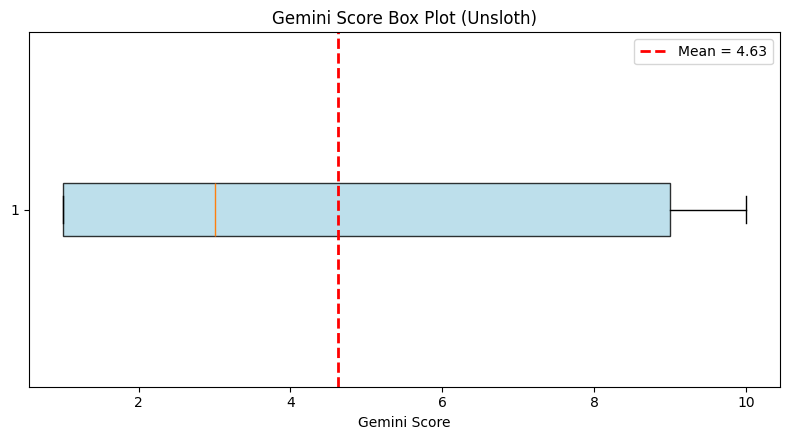

In [17]:
plt.figure(figsize=(8, 4.5))
plt.boxplot(scores_unsloth, vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue', alpha=0.8))
plt.axvline(scores_unsloth.mean(), color='red', linestyle='--', linewidth=2, label=f"Mean = {scores_unsloth.mean():.2f}")
plt.title('Gemini Score Box Plot (Unsloth)')
plt.xlabel('Gemini Score')
plt.legend()
plt.tight_layout()
plt.show()